# EDA: Zookeeper

Исследование по 11 пунктам чеклиста. Данные приходят через Python-функцию из `util/loghub_systems.py`; вычисления вынесены в `util/loghub_eda.py`. Запуск: установить `requirements-eda-systems.txt`, выбрать это Python-окружение и выполнить **Restart Kernel → Run All**. Порядок ячеек самодостаточен.

Область анализа явно отмечена: полный поток и случайная выборка не смешиваются. Числа в таблицах вычисляются из данных, пропуски и ограничения сохраняются.

## 1. Происхождение данных

Логи сервиса ZooKeeper из лаборатории CUHK, агрегированные с 32 машин за 26+ дней. Каталог указывает 74 380 строк и 9,95 MiB. Анализируем весь файл. В нём есть уровни INFO/WARN/ERROR, но **нет разметки аномалий**. Состав нагрузки и полный процесс предварительной фильтрации не документированы.

Временные метки содержат год и миллисекунды, но не часовой пояс. Поля `myid` и адреса в контексте сообщения не считаем надёжной идентификацией хоста-источника: формат отдельного поля host не содержит.

Источники: [описание Zookeeper](https://github.com/logpai/loghub/tree/master/Zookeeper), [каталог LogHub](https://github.com/logpai/loghub), [неизменяемая версия архива Zenodo 8196385](https://zenodo.org/records/8196385). Размер и MD5 закреплены в загрузчике по метаданным Zenodo. LogHub разрешает исследовательское/академическое использование; при распространении нужно ссылаться на LogHub и статью. Заявление LogHub «по возможности без изменений» не является гарантией отсутствия фильтрации конкретного источника.

In [1]:
import sys
import platform
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, JSON

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "util" / "loghub_systems.py").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from util.loghub_systems import load_small, load_thunderbird, SOURCES
from util.loghub_eda import (
    reconstruct_events, quality_table, minute_counts, dense_minutes,
    time_summary, largest_gaps, zero_runs, distribution, drift,
    message_statistics, entity_counts, component_mentions,
    session_candidates, mine_templates, window_summary, alert_episodes,
)

SEED = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 140)
environment = {package: version(package) for package in ["numpy", "pandas", "matplotlib", "drain3", "nbclient"]}
display({"python": platform.python_version(), "executable": sys.executable, **environment})

{'python': '3.12.6',
 'executable': 'C:\\Users\\Georges\\Documents\\HSE\\year_project\\hse-ai-2026-cloud-anomaly-detection\\.venv\\Scripts\\python.exe',
 'numpy': '2.3.5',
 'pandas': '2.3.3',
 'matplotlib': '3.10.6',
 'drain3': '0.9.11',
 'nbclient': '0.10.2'}

In [2]:
NAME = "Zookeeper"
physical, source = load_small(NAME)
prefix = physical
events_all = reconstruct_events(physical)
events = events_all.loc[events_all.parse_ok].copy()
minutes = minute_counts(events)
SCOPE = "все физические строки и восстановленные события полного файла"
assert len(physical) == source["physical_lines"]
assert events_all.physical_line_count.sum() == len(physical)
assert minutes["count"].sum() == events.timestamp.notna().sum()
dense = dense_minutes(minutes)
display({"analysis_scope": SCOPE, "source": source["url"], "MD5 archive": source["archive_md5"], "SHA256 raw": source["sha256_raw"]})

{'analysis_scope': 'все физические строки и восстановленные события полного файла',
 'source': 'https://zenodo.org/records/8196385/files/Zookeeper.tar.gz?download=1',
 'MD5 archive': '11458b4f9fa0911c238f5c1189d4f2d4',
 'SHA256 raw': '5c793ff30e960e387845fa81e595977a9037bc4801ef67f6c3298622d5d4572a'}

## 2. Физическая организация

Архив tar.gz содержит текстовый `.log`. Читаем бинарные строки по LF, отдельно считаем CRLF, проверяем строгое декодирование UTF-8. При ошибке сохраняем строку с replacement-символом и учитываем ошибку; строки не исчезают молча. Отсутствие финального LF само по себе не доказывает обрыв. Наличие даты и PID зависит от источника.

ZooKeeper: `YYYY-MM-DD HH:MM:SS,mmm - LEVEL [context:Class@line] - message`. OpenSSH/Mac: `Mon day HH:MM:SS host process[pid]: message`, при этом Mac допускает пробелы в имени процесса и строки продолжения.

In [3]:
display(pd.Series({key: source.get(key, 0) for key in ["member", "member_bytes", "physical_lines", "bytes", "crlf", "lf", "no_final_lf", "invalid_utf8_lines"]}, name="source_fact"))
display(physical.dtypes.astype(str).to_frame("parsed_dtype"))

member                Zookeeper.log
member_bytes               10426438
physical_lines                74380
bytes                      10426438
crlf                          74380
lf                                0
no_final_lf                       0
invalid_utf8_lines                0
Name: source_fact, dtype: object

,parsed_dtype
line_no,int64
raw,object
parse_ok,bool
header_start,bool
message,object
host,object
component,object
level,object
pid,object
label,object


## 3. Первичный осмотр и качество

Ниже — **100 первых и 100 случайных строк целиком**, с номерами в исходном файле. Случайный отбор детерминирован. Дубли считаем по полному тексту, включая заголовок; это наблюдение, а не команда удалить записи. Выбросы и ошибки парсинга показываем отдельно.

В таблице различаются физические строки и события. Наличие многострочных событий проверяется после восстановления; это эвристика по границам заголовков.

In [4]:
with pd.option_context("display.max_rows", 100, "display.max_colwidth", None):
    display(prefix[["line_no", "raw"]].head(100))
    display(physical[["line_no", "raw"]].sample(n=min(100, len(physical)), random_state=SEED).sort_values("line_no"))

,line_no,raw
0,1,"2015-07-29 17:41:41,536 - INFO [main:QuorumPeerConfig@101] - Reading configuration from: /etc/zookeeper/conf/zoo.cfg"
1,2,"2015-07-29 17:41:41,544 - INFO [main:QuorumPeerConfig@334] - Defaulting to majority quorums"
2,3,"2015-07-29 17:41:41,555 - INFO [main:DatadirCleanupManager@78] - autopurge.snapRetainCount set to 3"
3,4,"2015-07-29 17:41:41,555 - INFO [main:DatadirCleanupManager@79] - autopurge.purgeInterval set to 0"
4,5,"2015-07-29 17:41:41,557 - INFO [main:DatadirCleanupManager@101] - Purge task is not scheduled."
5,6,"2015-07-29 17:41:41,579 - INFO [main:QuorumPeerMain@127] - Starting quorum peer"
6,7,"2015-07-29 17:41:41,609 - INFO [main:NIOServerCnxnFactory@94] - binding to port 0.0.0.0/0.0.0.0:2181"
7,8,"2015-07-29 17:41:41,648 - INFO [main:QuorumPeer@913] - tickTime set to 2000"
8,9,"2015-07-29 17:41:41,649 - INFO [main:QuorumPeer@933] - minSessionTimeout set to -1"
9,10,"2015-07-29 17:41:41,649 - INFO [main:QuorumPeer@944] - maxSessionTimeout set to -1"


,line_no,raw
549,550,"2015-07-29 19:14:24,243 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@762] - Connection broken for id 188978561024, my id = 1, error ="
1836,1837,"2015-07-29 19:17:54,603 - WARN [SendWorker:188978561024:QuorumCnxManager$SendWorker@679] - Interrupted while waiting for message on queue"
2107,2108,"2015-07-29 19:18:37,770 - WARN [SendWorker:188978561024:QuorumCnxManager$SendWorker@688] - Send worker leaving thread"
3304,3305,"2015-07-29 19:22:23,489 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@762] - Connection broken for id 188978561024, my id = 1, error ="
4645,4646,"2015-07-29 19:23:40,140 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@765] - Interrupting SendWorker"
5223,5224,"2015-07-29 19:24:10,407 - INFO [/10.10.34.11:3888:QuorumCnxManager$Listener@493] - Received connection request /10.10.34.13:58824"
5712,5713,"2015-07-29 19:24:40,263 - WARN [SendWorker:188978561024:QuorumCnxManager$SendWorker@688] - Send worker leaving thread"
7863,7864,"2015-07-29 19:28:35,155 - INFO [/10.10.34.11:3888:QuorumCnxManager$Listener@493] - Received connection request /10.10.34.11:47502"
8864,8865,"2015-07-29 19:29:25,371 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@762] - Connection broken for id 188978561024, my id = 1, error ="
8987,8988,"2015-07-29 19:29:31,955 - WARN [SendWorker:188978561024:QuorumCnxManager$SendWorker@688] - Send worker leaving thread"


In [5]:
quality = quality_table(physical, source, events_all)
display(quality.to_frame())
display(physical.loc[~physical.parse_ok, ["line_no", "raw"]].head(15))
display(events.loc[events.physical_line_count.gt(1), ["line_no", "physical_line_count", "message"]].head(5))
display(physical.loc[physical.raw.duplicated(keep=False), ["line_no", "raw"]].head(10))

,value
source_physical_lines (full),7.438000e+04
published_lines (reference),7.438000e+04
source_bytes (full),1.042644e+07
analyzed_physical_lines,7.438000e+04
analyzed_events,7.438000e+04
mean_line_characters,1.381780e+02
blank_lines,0.000000e+00
duplicate_raw_lines_beyond_first,1.988000e+03
unparsed_physical_lines,0.000000e+00
without_header_start,0.000000e+00


,line_no,raw


,line_no,physical_line_count,message


,line_no,raw
196,197,"2015-07-29 19:13:24,279 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@765] - Interrupting SendWorker"
198,199,"2015-07-29 19:13:24,279 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@765] - Interrupting SendWorker"
256,257,"2015-07-29 19:13:34,287 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@762] - Connection broken for id 188978561024, my id..."
257,258,"2015-07-29 19:13:34,288 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@765] - Interrupting SendWorker"
258,259,"2015-07-29 19:13:34,287 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@762] - Connection broken for id 188978561024, my id..."
260,261,"2015-07-29 19:13:34,288 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@765] - Interrupting SendWorker"
498,499,"2015-07-29 19:14:14,322 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@765] - Interrupting SendWorker"
500,501,"2015-07-29 19:14:14,322 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@765] - Interrupting SendWorker"
1695,1696,"2015-07-29 19:17:34,477 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@762] - Connection broken for id 188978561024, my id..."
1699,1700,"2015-07-29 19:17:34,477 - WARN [RecvWorker:188978561024:QuorumCnxManager$RecvWorker@762] - Connection broken for id 188978561024, my id..."


## 4. Время

Порядок в файле и хронологический порядок проверяются отдельно. Повторяющиеся timestamps допустимы для одновременных событий. Пустые интервалы означают отсутствие записей в опубликованном файле; без метрик доступности нельзя отличить простой системы от потери логов.

В ZooKeeper разрешение 1 ms; OpenSSH и Mac — 1 s. Часовой пояс не указан, поэтому timestamps остаются timezone-naive. Для syslog годы синтетические, переход года учитывается. Мы не утверждаем, что все машины использовали один пояс.

In [6]:
display(time_summary(events).to_frame("analyzed_events"))
display(zero_runs(minutes).head(10))

display(largest_gaps(events))

,analyzed_events
valid_timestamp_events,74380
missing_timestamps,0
first_in_file,2015-07-29 17:41:41.536000
last_in_file,2015-08-25 11:26:28.159000
chronological_min,2015-07-29 17:41:41.536000
chronological_max,2015-08-25 11:26:28.159000
span,26 days 17:44:46.623000
backsteps_file_order,415
repeated_timestamps_beyond_first,40990
fractional_second_events,73461


,start,end_exclusive,minutes
133,2015-08-11 06:09:00,2015-08-18 16:09:00,10680
123,2015-07-31 21:45:00,2015-08-07 07:27:00,9222
124,2015-08-07 07:28:00,2015-08-10 17:52:00,4944
144,2015-08-21 15:56:00,2015-08-24 10:21:00,3985
134,2015-08-18 16:10:00,2015-08-20 13:12:00,2702
143,2015-08-20 19:34:00,2015-08-21 15:55:00,1221
22,2015-07-29 23:59:00,2015-07-30 11:31:00,692
132,2015-08-10 18:36:00,2015-08-11 06:07:00,691
103,2015-07-31 00:41:00,2015-07-31 11:00:00,619
145,2015-08-24 10:22:00,2015-08-24 15:26:00,304


,from,to,gap_seconds
28859,2015-08-11 06:08:14.001,2015-08-18 16:09:11.869,640857.868
27599,2015-07-31 21:44:52.004,2015-08-07 07:27:27.082,553355.078
27712,2015-08-07 07:27:49.692,2015-08-10 17:52:37.611,296687.919
30393,2015-08-21 15:55:20.000,2015-08-24 10:21:09.060,239149.060
28994,2015-08-18 16:09:36.889,2015-08-20 13:12:37.032,162180.143
30274,2015-08-20 19:33:16.006,2015-08-21 15:55:03.341,73307.335
28848,2015-08-10 18:35:20.001,2015-08-11 06:07:54.760,41554.759
21614,2015-07-29 23:58:52.000,2015-07-30 11:31:21.273,41549.273
25911,2015-07-31 00:40:12.000,2015-07-31 11:00:51.272,37239.272
30419,2015-08-24 10:21:46.003,2015-08-24 15:26:54.374,18308.371


## 5. Объём, производители и изменение распределений

Интенсивность считается на полном временном диапазоне с нулевыми минутами. Крайние сутки/часы могут быть неполными. Средние по часу суток — разведочный профиль, а не доказанная сезонность: для этого нужны несколько сопоставимых циклов и модель нагрузки.

Уровни severity используем только из явного поля. Слова `error`, `failed` и категории alert не превращаем в INFO/ERROR. `<missing>` означает, что поле отсутствует. Для ZooKeeper host недоступен; для Mac разные имена не доказывают несколько физических машин. TVD — половина суммы модулей разностей долей между первой и второй половинами периода (0 = одинаковые распределения, 1 = непересекающиеся).

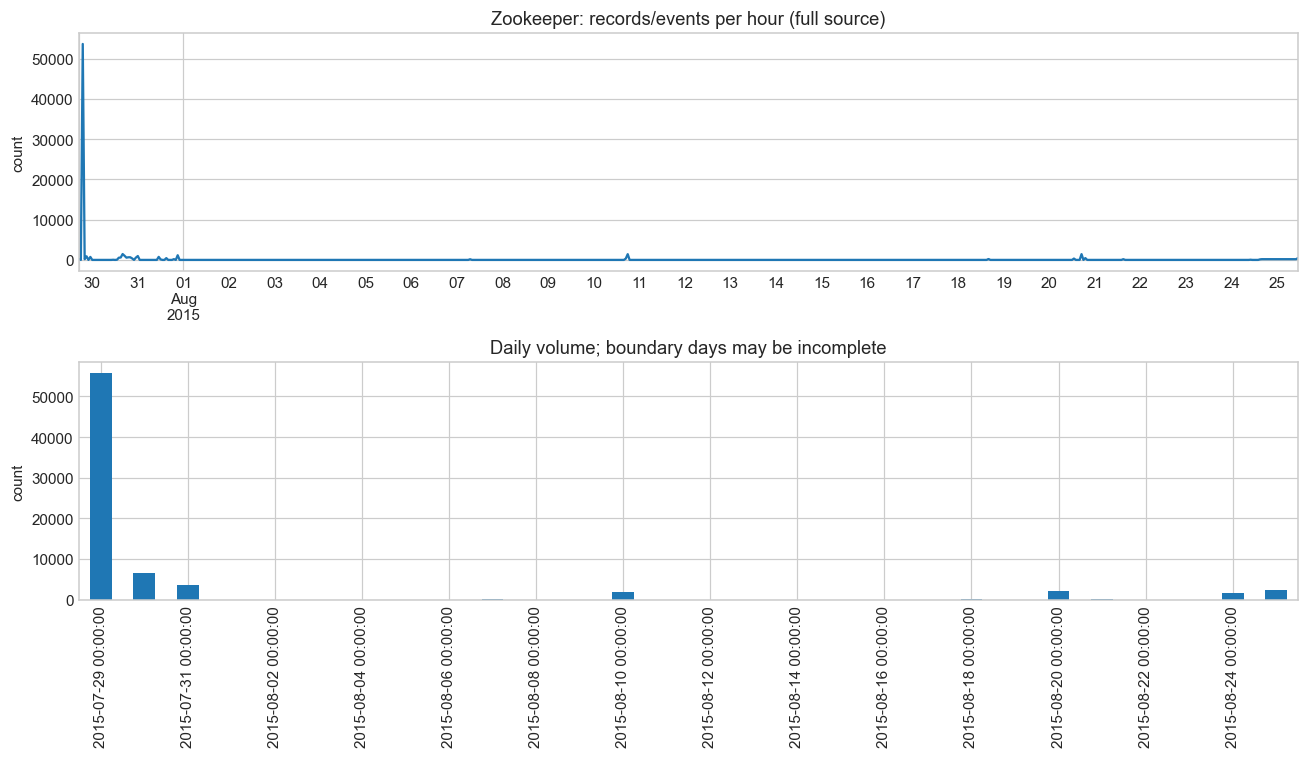

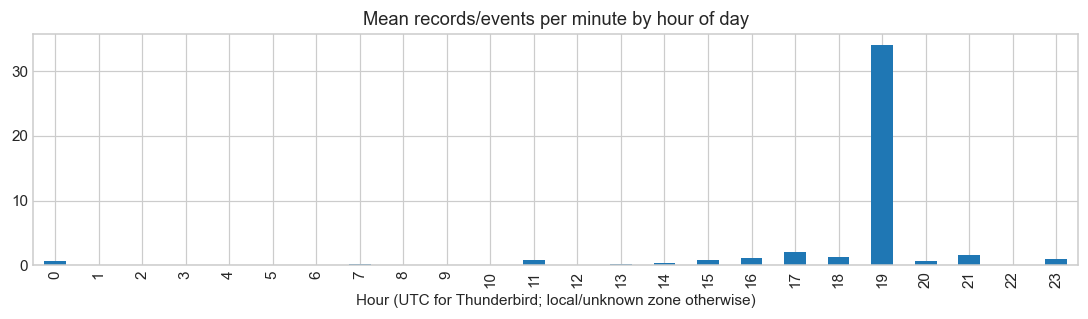

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
dense["count"].resample("1h").sum().plot(ax=axes[0], title=f"{NAME}: records/events per hour (full source)")
dense["count"].resample("1D").sum().plot.bar(ax=axes[1], title="Daily volume; boundary days may be incomplete")
axes[1].set_xticks(axes[1].get_xticks()[::max(1, len(dense.resample("1D").sum()) // 12)])
for ax in axes:
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(10, 3))
dense.groupby(dense.index.hour)["count"].mean().plot.bar(ax=ax, title="Mean records/events per minute by hour of day")
ax.set_xlabel("Hour (UTC for Thunderbird; local/unknown zone otherwise)")
plt.tight_layout()
plt.show()

In [8]:
for column in ["component", "host", "level"]:
    display(Markdown(f"**{column}: частоты и изменение долей ({SCOPE})**"))
    display(distribution(events, column).head(12))
    changes, tvd = drift(events, column)
    display({"total_variation_distance": tvd})
    display(changes.head(8))

**component: частоты и изменение долей (все физические строки и восстановленные события полного файла)**

,count,fraction
component,,
QuorumCnxManager$SendWorker,20780,0.279376
QuorumCnxManager$RecvWorker,20778,0.279349
QuorumCnxManager$Listener,10465,0.140696
ZooKeeperServer,7402,0.099516
NIOServerCnxn,3772,0.050713
QuorumCnxManager,2604,0.035009
NIOServerCnxnFactory,2056,0.027642
FastLeaderElection,1876,0.025222
PrepRequestProcessor,1813,0.024375


{'total_variation_distance': 0.7771710831022283}

period,first_half,second_half,delta
component,,,
QuorumCnxManager,0.002599,0.363854,0.361255
QuorumCnxManager$SendWorker,0.306822,0.000899,-0.305923
QuorumCnxManager$RecvWorker,0.306793,0.000899,-0.305893
FastLeaderElection,0.006499,0.215196,0.208697
QuorumCnxManager$Listener,0.154297,0.002697,-0.151600
ZooKeeperServer,0.094008,0.155402,0.061394
NIOServerCnxn,0.046081,0.097707,0.051626
NIOServerCnxnFactory,0.024665,0.057845,0.033180


**host: частоты и изменение долей (все физические строки и восстановленные события полного файла)**

,count,fraction
host,,
<missing>,74380,1.0


... (2 outputs left out)

**level: частоты и изменение долей (все физические строки и восстановленные события полного файла)**

,count,fraction
level,,
WARN,48507,0.652151
INFO,25256,0.339554
ERROR,617,0.008295


{'total_variation_distance': 0.22787008463188207}

period,first_half,second_half,delta
level,,,
INFO,0.319110,0.54698,0.227870
WARN,0.671821,0.45257,-0.219251
ERROR,0.009068,0.00045,-0.008619


## 6. Сообщения

Длины измеряем в символах Unicode. Выброс — выше Q3 + 1,5×IQR, это статистическое правило, а не метка аномалии. Слова: латинские буквенные токены длиной от двух символов, lowercase, без stop-word фильтра. Биграммы не пересекают границы сообщений. Редкие токены и сообщения сохраняют параметры, поэтому их редкость ещё не означает новое поведение. Ссылки на компоненты ищем среди 20 наиболее активных имён; совпадение текста не устанавливает сетевую зависимость.

,message_characters
count,74380.000000
mean,47.499462
std,22.177322
min,7.000000
1%,23.000000
50%,46.000000
90%,64.000000
95%,95.000000
99%,97.000000
max,295.000000


{'IQR_cutoff': 106.0, 'outlier_events': 676}

,line_no,message_length,message
51,52,295,Server environment:java.class.path=/etc/zookeeper/conf:/usr/share/java/jline.jar:/usr/share/java/log4j-1.2.jar:/usr/share/java/xercesImp...
19073,19074,295,Server environment:java.class.path=/etc/zookeeper/conf:/usr/share/java/jline.jar:/usr/share/java/log4j-1.2.jar:/usr/share/java/xercesImp...
21030,21031,295,Server environment:java.class.path=/etc/zookeeper/conf:/usr/share/java/jline.jar:/usr/share/java/log4j-1.2.jar:/usr/share/java/xercesImp...
21079,21080,295,Server environment:java.class.path=/etc/zookeeper/conf:/usr/share/java/jline.jar:/usr/share/java/log4j-1.2.jar:/usr/share/java/xercesImp...
21196,21197,295,Server environment:java.class.path=/etc/zookeeper/conf:/usr/share/java/jline.jar:/usr/share/java/log4j-1.2.jar:/usr/share/java/xercesImp...


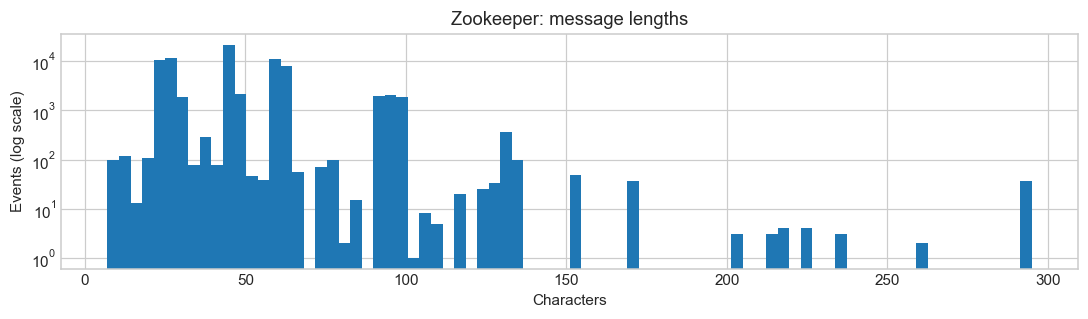

**words: самые частые и редкие**

,token,count
0,connection,26634
1,for,26510
2,id,20833
3,request,12303
4,my,10982
5,while,10978
6,error,10430
7,received,10429
8,on,10422
9,broken,10392


,token,count
298,afecda,1
299,baff,1
300,ccb,1
301,ebf,1
302,ecaa,1
303,edbbb,1
304,fac,1
305,fe,1
294,acceptor,2
295,ff,2


**bigrams: самые частые и редкие**

,token,count
0,connection request,12290
1,my id,10441
2,received connection,10429
3,for id,10392
4,id error,10392
5,id my,10392
6,interrupting sendworker,10390
7,leaving thread,10390
8,send worker,10390
9,worker leaving,10390


,token,count
618,af zxid,1
619,as xf,1
620,ba txntype,1
621,baff zxid,1
622,bb txntype,1
623,bd txntype,1
624,be txntype,1
625,client fdb,1
626,cxid af,1
627,cxid baff,1


... (2 outputs left out)

,count
message,
Send worker leaving thread,10390
Interrupting SendWorker,10390
Interrupted while waiting for message on queue,10386
"Connection broken for id 188978561024, my id = 1, error =",3492
"Connection broken for id 188978561024, my id = 2, error =",3432
"Connection broken for id 188978561024, my id = 3, error =",3432
caught end of stream exception,1670
Cannot open channel to 3 at election address /10.10.34.13:3888,1289
Cannot open channel to 2 at election address /10.10.34.12:3888,1276


,count
singleton_message,
Sending snapshot last zxid of peer is 0xd0000001b zxid of leader is 0xf00000000sent zxid of db as 0xf00000000,1
"New election. My id = 1, proposed zxid=0x0",1
Established session 0x34f4a63146b004a with negotiated timeout 10000 for client /10.10.34.40:49497,1
Closed socket connection for client /10.10.34.29:44549 which had sessionid 0x34f4a63146b0046,1
Closed socket connection for client /10.10.34.38:46110 which had sessionid 0x34f4a63146b0048,1
Closed socket connection for client /10.10.34.40:49497 which had sessionid 0x34f4a63146b004a,1
Closed socket connection for client /10.10.34.39:54740 which had sessionid 0x34f4a63146b0049,1
"New election. My id = 3, proposed zxid=0xc0000018f",1
Accepted socket connection from /10.10.34.39:54740,1


,count
message_seen_2_to_5,
Snapshotting: 0x8000000bc to /var/lib/zookeeper/version-2/snapshot.8000000bc,5
Reading snapshot /var/lib/zookeeper/version-2/snapshot.700000000,5
"Notification: 3 (n.leader), 0x300000dcd (n.zxid), 0x4 (n.round), LOOKING (n.state), 1 (n.sid), 0x3 (n.peerEPoch), LOOKING (my state)",5
Reading snapshot /var/lib/zookeeper/version-2/snapshot.d0000001b,5
"Connection broken for id 2, my id = 3, error =",5
"Unexpected exception, tries=0, connecting to /10.10.34.13:2888",5
Reading snapshot /var/lib/zookeeper/version-2/snapshot.100001564,5
Snapshotting: 0x700000197 to /var/lib/zookeeper/version-2/snapshot.700000197,4
"Notification: 3 (n.leader), 0x300000dcd (n.zxid), 0x4 (n.round), LOOKING (n.state), 2 (n.sid), 0x3 (n.peerEPoch), LOOKING (my state)",4


,producer,mentioned_component,events
0,NIOServerCnxn,ZooKeeperServer,159
1,LearnerHandler,Follower,68
2,LearnerHandler,QuorumPeer,34


In [9]:
text_stats = message_statistics(events)
display(text_stats["lengths"].to_frame("message_characters"))
display({"IQR_cutoff": text_stats["outlier_cutoff_IQR"], "outlier_events": text_stats["outliers"]})
display(events.nlargest(5, "message_length")[["line_no", "message_length", "message"]])
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(events.message_length, bins=80, log=True)
ax.set(title=f"{NAME}: message lengths", xlabel="Characters", ylabel="Events (log scale)")
plt.tight_layout()
plt.show()
for kind in ["words", "bigrams"]:
    display(Markdown(f"**{kind}: самые частые и редкие**"))
    display(text_stats[kind].head(12))
    display(text_stats[kind].sort_values(["count", "token"]).head(12))
characters = text_stats["characters"].to_frame("characters")
characters["fraction"] = characters.characters / characters.characters.sum()
display(characters)
display(text_stats["frequency_bands"].to_frame("unique_message_count"))
display(text_stats["messages"].head(10).rename_axis("message").to_frame("count"))
display(text_stats["messages"].loc[lambda s: s.eq(1)].head(10).rename_axis("singleton_message").to_frame("count"))
display(text_stats["messages"].loc[lambda s: s.between(2, 5)].head(10).rename_axis("message_seen_2_to_5").to_frame("count"))
display(component_mentions(events))

## 7. Сущности и кандидаты в сессии

Регулярные выражения выделяют IPv4/IPv6, порты, UUID, пути, URL, кандидаты в хэши и устройства, явные session ID. Синтаксис IP проверяется через `ipaddress`, порты ограничены 0–65535. Даже корректная по форме последовательность может оказаться частью другого идентификатора; это не подтверждение сетевой роли сущности. Пути, хэши и устройства — **кандидаты**, а не подтверждённые типы: 32 hex-символа могут быть ID, `/10.0.0.1` — адресом, а не путём. Классы могут пересекаться; их суммы нельзя складывать как число сущностей. Ищем в сообщениях, без полей заголовка.

ZooKeeper: явный `session id 0x…`. OpenSSH: `(host, PID, сегмент активности с разрывом >30 минут)` — эвристика, PID переиспользуется и не равен ID соединения. Для Mac и Thunderbird универсальный session ID не заявляем.

In [10]:
entities, entity_examples = entity_counts(events)
display(entities)
for kind, examples in entity_examples.items():
    display(Markdown(f"**{kind}: примеры и число упоминаний**"))
    display(examples)
sessions = session_candidates(events, NAME)
display({"candidate_sessions": len(sessions)})
display(sessions.head(10))

,unique,mentions,events_with_entity
entity,,,
ipv4,33,23276,23204
ipv6,0,0,0
port,9986,23276,23204
uuid,0,0,0
path,65,23590,23541
url,0,0,0
hash_candidate,0,0,0
device_candidate,0,0,0
session_id,1791,3856,3856


**ipv4: примеры и число упоминаний**

,value,mentions
0,10.10.34.11,6506
1,10.10.34.13,6448
2,10.10.34.12,6259
3,10.10.34.14,207
4,10.10.34.18,182
5,10.10.34.16,177
6,10.10.34.19,176
7,10.10.34.25,176
8,10.10.34.22,176
9,10.10.34.17,173


**ipv6: примеры и число упоминаний**

,value,mentions


**port: примеры и число упоминаний**

... (11 outputs left out)

**session_id: примеры и число упоминаний**

,value,mentions
0,0x0,159
1,0x14ed93111f20012,6
2,0x24ed93119420016,6
3,0x14f05578bd80013,6
4,0x14f05578bd80014,6
5,0x14f05578bd80015,6
6,0x14f05578bd80016,6
7,0x14f05578bd80017,6
8,0x14f05578bd80018,6
9,0x14f05578bd80019,6


{'candidate_sessions': 1791}

,events,first,last,duration_seconds
session,,,,
0x0,159,2015-07-29 19:53:11.552,2015-08-20 17:14:15.773,1891264.221
0x14f05578bd80016,6,2015-08-10 18:12:43.814,2015-08-10 18:25:58.001,794.187
0x24f0557806a0021,6,2015-08-10 18:12:49.919,2015-08-10 18:25:48.001,778.082
0x24f0557806a0022,6,2015-08-10 18:12:50.551,2015-08-10 18:25:52.000,781.449
0x24f0557806a0023,6,2015-08-10 18:12:57.142,2015-08-10 18:25:56.000,778.858
0x24ed93119420016,6,2015-07-29 19:54:05.546,2015-07-29 19:54:58.000,52.454
0x24f0557806a0019,6,2015-08-10 18:12:47.215,2015-08-10 18:25:58.000,790.785
0x34f0557885e0016,6,2015-08-10 18:12:42.789,2015-08-10 18:25:58.000,795.211
0x14f05578bd8001d,6,2015-08-10 18:12:46.637,2015-08-10 18:25:48.001,781.364


## 8. Шаблоны событий

Используем [Drain3](https://github.com/logpai/Drain3), `depth=4`, `sim_th=0.4`, с масками UUID/IP/HEX/NUM. Обучаем на текстах сообщений в порядке файла, без времён и labels. Для каждого cluster ID показываем **финальный** шаблон, потому что при обучении он обобщается. Это исследовательская кластеризация, не оценка точности парсинга. Время первого/последнего наблюдения и число дней не доказывают рождение/исчезновение события вне периода наблюдения. Для Thunderbird это особенно существенно: редкий шаблон мог не попасть в выборку.

{'templates': 77, 'singleton_templates': 0}

,count,template,first,last,observed_days
template_id,,,,,
20,10429,Received connection request /<IP>:<NUM>,2015-07-29 17:42:28.310,2015-08-25 11:26:27.891,7
31,10390,Interrupting SendWorker,2015-07-29 19:04:02.386,2015-08-25 11:20:12.465,4
33,10390,Send worker leaving thread,2015-07-29 19:04:02.387,2015-08-25 11:20:12.467,4
30,10388,"Connection broken for id <NUM>, my id = <NUM>, error =",2015-07-29 19:04:02.385,2015-08-25 11:20:12.465,4
32,10386,Interrupted while waiting for message on queue,2015-07-29 19:04:02.387,2015-08-25 11:20:12.466,4
18,2584,Cannot open channel to <NUM> at election address /<IP>:<NUM>,2015-07-29 17:41:41.733,2015-08-25 11:23:57.731,8
36,2020,Accepted socket connection from /<IP>:<NUM>,2015-07-29 19:37:24.535,2015-08-21 15:55:14.153,6
38,1861,Client attempting to <*> <*> <*> at /<IP>:<NUM>,2015-07-29 19:37:24.548,2015-08-21 15:55:14.154,6
37,1861,Connection request from old client /<IP>:<NUM>; will be dropped if server is in r-o mode,2015-07-29 19:37:24.546,2015-08-21 15:55:14.153,6


,count,template,first,last,observed_days
template_id,,,,,
72,2,PrepRequestProcessor exited loop!,2015-07-30 23:43:23.610,2015-08-20 17:12:29.084,2
73,2,SessionTrackerImpl exited loop!,2015-07-30 23:43:24.000,2015-08-20 17:12:30.000,2
70,2,Shutdown called,2015-07-30 23:43:23.609,2015-08-20 17:12:29.074,2
71,2,exception while shutting down acceptor: java.net.SocketException: Socket closed,2015-07-30 23:43:23.609,2015-08-20 17:12:29.075,2
13,3,acceptedEpoch not found! Creating with a reasonable default of <NUM>. This should only happen when you are upgrading your installation,2015-07-29 17:41:41.683,2015-07-29 17:42:48.468,1
12,3,currentEpoch not found! Creating with a reasonable default of <NUM>. This should only happen when you are upgrading your installation,2015-07-29 17:41:41.680,2015-07-29 17:42:48.465,1
43,4,Exception when using channel: for id <NUM> my id = <NUM> error = java.net.SocketException: Broken pipe,2015-07-29 19:53:10.594,2015-07-30 23:52:56.627,2
74,6,Getting a snapshot from leader,2015-07-29 17:46:14.656,2015-08-25 11:26:28.145,4
65,6,Sending snapshot last zxid of peer is <HEX> zxid of leader is <*> zxid of db as <HEX>,2015-07-29 17:46:17.173,2015-08-25 11:26:28.159,4


,count,template,first,last,observed_days
template_id,,,,,
1,36,Reading configuration from: /etc/zookeeper/conf/zoo.cfg,2015-07-29 17:41:41.536,2015-08-25 11:26:27.571,8
2,36,Defaulting to majority quorums,2015-07-29 17:41:41.544,2015-08-25 11:26:27.584,8
4,36,autopurge.purgeInterval set to <NUM>,2015-07-29 17:41:41.555,2015-08-25 11:26:27.599,8
3,36,autopurge.snapRetainCount set to <NUM>,2015-07-29 17:41:41.555,2015-08-25 11:26:27.599,8
5,36,Purge task is not scheduled.,2015-07-29 17:41:41.557,2015-08-25 11:26:27.600,8
6,36,Starting quorum peer,2015-07-29 17:41:41.579,2015-08-25 11:26:27.623,8
7,36,binding to port <IP>/<IP>:<NUM>,2015-07-29 17:41:41.609,2015-08-25 11:26:27.649,8
8,36,tickTime set to <NUM>,2015-07-29 17:41:41.648,2015-08-25 11:26:27.688,8
11,36,initLimit set to <NUM>,2015-07-29 17:41:41.649,2015-08-25 11:26:27.689,8


,count,template,first,last,observed_days,days_since_last
template_id,,,,,,
12,3,currentEpoch not found! Creating with a reasonable default of <NUM>. This should only happen when you are upgrading your installation,2015-07-29 17:41:41.680,2015-07-29 17:42:48.465,1,26.738654
13,3,acceptedEpoch not found! Creating with a reasonable default of <NUM>. This should only happen when you are upgrading your installation,2015-07-29 17:41:41.683,2015-07-29 17:42:48.468,1,26.738654
45,8,Exception causing close of session <HEX> due to java.io.IOException: Connection reset by peer,2015-07-29 19:53:04.177,2015-07-29 19:55:01.340,1,26.646838
43,4,Exception when using channel: for id <NUM> my id = <NUM> error = java.net.SocketException: Broken pipe,2015-07-29 19:53:10.594,2015-07-30 23:52:56.627,2,25.481615
77,19,Got user-level KeeperException when processing sessionid:<HEX> type:create cxid:<HEX> zxid:<HEX> txntype:-<NUM> reqpath:n/a Error <*> Er...,2015-07-29 19:37:27.211,2015-07-31 21:33:04.375,3,24.578747
42,55,Revalidating client: <HEX>,2015-07-29 19:53:01.214,2015-08-20 17:12:22.607,3,4.759786
69,590,******* GOODBYE /<IP>:<NUM> ********,2015-07-29 19:03:35.421,2015-08-20 17:12:28.082,4,4.759723
68,590,Unexpected exception causing shutdown while sock still open,2015-07-29 19:03:35.413,2015-08-20 17:12:28.082,4,4.759723
70,2,Shutdown called,2015-07-30 23:43:23.609,2015-08-20 17:12:29.074,2,4.759712


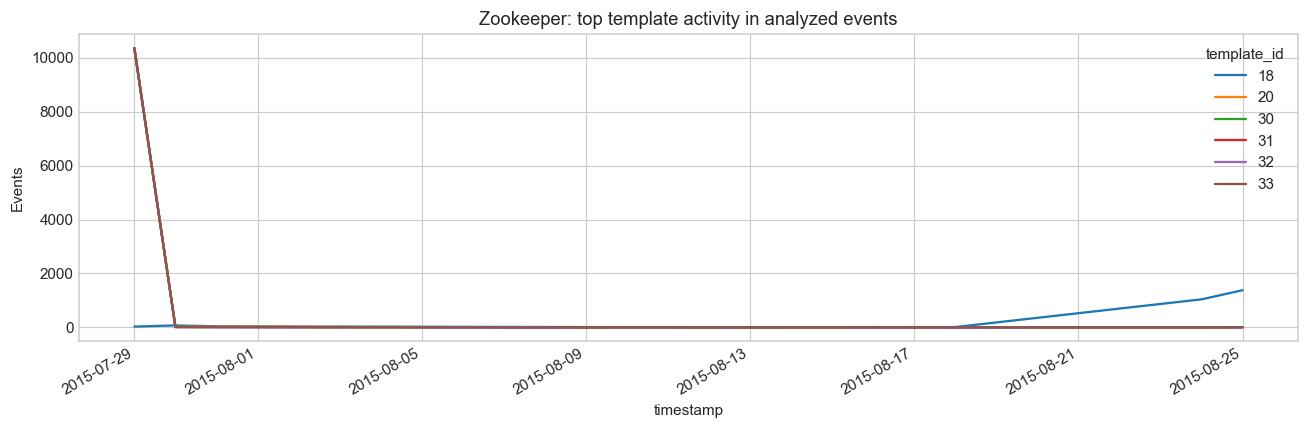

In [11]:
events, templates = mine_templates(events)
assert templates["count"].sum() == len(events)
display({"templates": len(templates), "singleton_templates": int(templates["count"].eq(1).sum())})
display(templates.head(12))
display(templates.sort_values(["count", "template"]).head(12))
display(templates.sort_values("first").head(10))
observation_end = events.timestamp.max()
template_inactivity = templates.assign(days_since_last=(observation_end - templates["last"]).dt.total_seconds() / 86400)
display(template_inactivity.sort_values("days_since_last", ascending=False).head(10))
top_ids = templates.head(6).index
activity = events.loc[events.template_id.isin(top_ids)].groupby([pd.Grouper(key="timestamp", freq="1D"), "template_id"]).size().unstack(fill_value=0)
activity.plot(figsize=(12, 4), title=f"{NAME}: top template activity in analyzed events")
plt.ylabel("Events")
plt.tight_layout()
plt.show()

## 9. Разметка и аномалии

Официальной разметки аномалий нет. Поэтому долю аномалий, длительность размеченных инцидентов, label-exclusive шаблоны и десять размеченных аномалий оценить нельзя. INFO/WARN/ERROR, `Failed password`, выбросы объёма и редкие шаблоны не подменяют ground truth. Ниже читаем десять **подозрительных по тексту примеров**, чтобы предложить будущие правила разметки; это не подтверждённые инциденты.

In [12]:
assert events.is_anomaly.isna().all()
candidates = events.loc[events.message.str.contains(r"error|fail|warn|exception|invalid|broken|timeout", case=False, regex=True)]
with pd.option_context("display.max_colwidth", None):
    display(candidates.drop_duplicates("message").head(10)[["line_no", "timestamp", "component", "message"]])
display({"text_rule_candidate_events": len(candidates), "ground_truth_anomaly_count": "unknown"})

,line_no,timestamp,component,message
8,9,2015-07-29 17:41:41.649,QuorumPeer,minSessionTimeout set to -1
9,10,2015-07-29 17:41:41.649,QuorumPeer,maxSessionTimeout set to -1
61,62,2015-07-29 17:42:28.554,ZooKeeperServer,Created server with tickTime 2000 minSessionTimeout 4000 maxSessionTimeout 40000 datadir /var/lib/zookeeper/version-2 snapdir /var/lib/zookeeper/version-2
79,80,2015-07-29 19:04:02.385,QuorumCnxManager$RecvWorker,"Connection broken for id 188978561024, my id = 1, error ="
17549,17550,2015-07-29 19:37:25.348,ZooKeeperServer,Established session 0x14ed93111f20000 with negotiated timeout 10000 for client /10.10.34.12:45539
17550,17551,2015-07-29 19:37:25.349,ZooKeeperServer,Established session 0x14ed93111f20001 with negotiated timeout 10000 for client /10.10.34.12:45541
17551,17552,2015-07-29 19:37:25.350,ZooKeeperServer,Established session 0x14ed93111f20002 with negotiated timeout 10000 for client /10.10.34.12:45542
17555,17556,2015-07-29 19:37:25.418,ZooKeeperServer,Established session 0x14ed93111f20003 with negotiated timeout 10000 for client /10.10.34.13:37036
17559,17560,2015-07-29 19:48:28.927,ZooKeeperServer,Established session 0x14ed93111f20004 with negotiated timeout 10000 for client /10.10.34.15:34816
17563,17564,2015-07-29 19:48:29.233,ZooKeeperServer,Established session 0x14ed93111f20005 with negotiated timeout 10000 for client /10.10.34.18:42772


{'text_rule_candidate_events': 16625, 'ground_truth_anomaly_count': 'unknown'}

## 10. Временные окна

Сравниваем фиксированные непересекающиеся окна 1, 5, 15, 60 минут и сутки. Сетка покрывает весь наблюдаемый период, нулевые окна сохраняются. Крайние окна частичны. `above_p99` — разведочный индикатор концентрации; p99 не является порогом доказанной аномалии. Дисперсия/среднее описывает неравномерность нагрузки, но без стационарности не служит тестом на аномалии.

Считаем восстановленные события с валидным временем. Для Mac скрытые syslog-повторы не разворачиваем, поэтому это интенсивность опубликованных событий, не всех событий системы.

,windows,empty,empty_fraction,mean,median,p99,max,above_p99,variance_over_mean
window_minutes,,,,,,,,,
1,38506,36968,0.960058,1.931647,0.0,3.00,3510,339,2114.426706
5,7702,7308,0.948844,9.657232,0.0,66.97,16470,78,9064.422699
15,2568,2409,0.938084,28.964174,0.0,285.28,27857,26,18380.521610
60,643,590,0.917574,115.676516,0.0,929.76,53620,7,38806.119029
1440,28,17,0.607143,2656.428571,0.0,42373.25,55637,1,41410.303694


,count,alerts
2015-07-29 19:28:00,3510,NaN
2015-07-29 19:29:00,3440,NaN
2015-07-29 19:34:00,3395,NaN
2015-07-29 19:33:00,3355,NaN
2015-07-29 19:23:00,3240,NaN
2015-07-29 19:24:00,3240,NaN
2015-07-29 19:30:00,3240,NaN
2015-07-29 19:31:00,3240,NaN
2015-07-29 19:32:00,3240,NaN
2015-07-29 19:35:00,3240,NaN


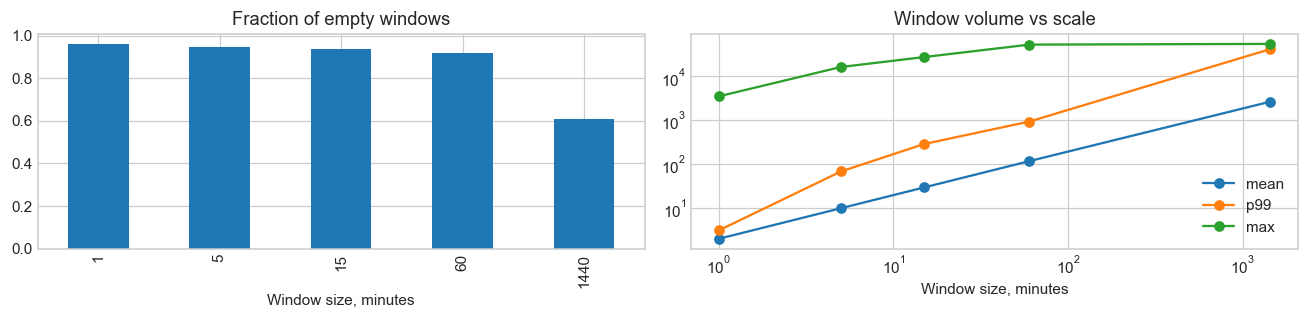

In [13]:
windows = window_summary(minutes)
display(windows)
display(dense.nlargest(10, "count"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
windows.empty_fraction.plot.bar(ax=axes[0], title="Fraction of empty windows")
windows[["mean", "p99", "max"]].plot(ax=axes[1], marker="o", logy=True, logx=True, title="Window volume vs scale")
axes[0].set_xlabel("Window size, minutes")
axes[1].set_xlabel("Window size, minutes")
plt.tight_layout()
plt.show()

## 11. Проверяемый дайджест и открытые вопросы

Следующая ячейка собирает ключевые числа из текущего запуска. В финальной Markdown-ячейке — их интерпретация и ограничения.

In [14]:
digest = {
    "dataset": NAME,
    "physical_lines_full": int(source["physical_lines"]),
    "analyzed_events": len(events),
    "parse_fraction_physical": float(physical.parse_ok.mean()),
    "duplicates_in_analyzed_physical": int(physical.raw.duplicated().sum()),
    "multiline_events": int(events.physical_line_count.gt(1).sum()),
    "start": str(dense.index.min()), "end": str(dense.index.max()),
    "templates": len(templates), "singleton_templates": int(templates["count"].eq(1).sum()),
    "message_length_median": float(events.message_length.median()),
    "empty_minutes_fraction": float(windows.loc[1, "empty_fraction"]),
    "busiest_minute": str(dense["count"].idxmax()),
    "busiest_minute_count": int(dense["count"].max()),
    "top_component": str(events.component.value_counts().index[0]),
    "top_template": str(templates.iloc[0].template),
    "top_template_count": int(templates.iloc[0]["count"]),
    "entity_unique": {k: int(v) for k, v in entities["unique"].items()},
    "session_candidates": len(sessions),
    "unparsed_header_lines": int((physical.header_start & ~physical.parse_ok).sum()),
}

display(JSON(digest))

<IPython.core.display.JSON object>

### Выводы по Zookeeper

- Полный источник: **74,380 физических строк**. Анализ текстов: **74,380 событий**.
- Медиана длины сообщения — **46 символов**. Drain3 выделил **77 шаблонов**, из них **0** встречаются один раз.
- На полной временной сетке **96.01% пустых минут**. Максимум — **3,510 событий/минуту**, 2015-07-29 19:28:00. Крайние окна частичны.

WARN составляет 48 507 из 74 380 записей (65,2%); INFO — 25 256, ERROR — 617. Следовательно, WARN здесь нельзя автоматически считать аномалией. Чтение десяти примеров выявляет ложные срабатывания текстового правила: слово `timeout` встречается в настройках и успешном `Established session`, то есть само по себе не сигнализирует об ошибке. Встречается и реальный текст `Connection broken`, но для определения инцидента необходим контекст кластера. Самый частый шаблон — получение запроса соединения (10 429 записей).

В файле 1 988 полных дубликатов сверх первого вхождения и 415 инверсий времени. Их нельзя автоматически удалять: агрегирование нескольких машин и повторная доставка могут давать одинаковые строки. Временной диапазон — 29.07–25.08.2015, но 96,0% минут пусты; крупнейшая непрерывная пустота — 10 680 минут. Это нерегулярный набор наблюдений, а не доказательство непрерывной записи 32 машин.

Выделено 1 791 явных session ID и 33 IPv4-адреса в сообщениях. IP могут принадлежать клиентам или удалённым участникам; это не число источников лога. Поле host отсутствует. Для дальнейшей модели полезны последовательности session ID, типы событий выборов лидера и изменения профиля соединений; сначала нужно выяснить полноту наблюдения.

**Открытые вопросы:** почему присутствуют многодневные пробелы; как были объединены логи машин; синхронизировались ли их часы; какие сессии/выборы действительно сопровождались деградацией? Без ответа пустые окна и WARN остаются признаками, а не labels.

**Воспроизводимость:** полный архив Zenodo с закреплённым MD5, контроль SHA-256, фиксированный seed, явные правила парсинга, версии библиотек в начале. Подсчёты соответствуют параметрам этого выполненного ноутбука. Все 11 пунктов чеклиста рассмотрены; ограничения разметки и неизвестные поля указаны явно.